In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [14]:
from google.colab import files

uploaded = files.upload()

Saving StudentsPerformance.csv to StudentsPerformance (5).csv


In [15]:
import pandas as pd

# Read the uploaded CSV file
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

# Display first five rows
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [16]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (1000, 8)

Column Names:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [17]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [18]:

# Calculate average marks for every student

df["Average Score"] = df[
    ["math score", "reading score", "writing score"]
].mean(axis=1)

# Display the results
df[["math score", "reading score",
    "writing score", "Average Score"]].head(10)


,math score,reading score,writing score,Average Score
0,72,72,74,72.666667
1,69,90,88,82.333333
2,90,95,93,92.666667
3,47,57,44,49.333333
4,76,78,75,76.333333
5,71,83,78,77.333333
6,88,95,92,91.666667
7,40,43,39,40.666667
8,64,64,67,65.000000
9,38,60,50,49.333333


In [19]:

def assign_grade(score):
    if score >= 90:
        return "A"
    elif score >= 80:
        return "B"
    elif score >= 70:
        return "C"
    elif score >= 60:
        return "D"
    else:
        return "F"

# Apply grades to all students
df["Grade"] = df["Average Score"].apply(assign_grade)

# Display student averages and grades
df[["Average Score", "Grade"]].head(10)


,Average Score,Grade
0,72.666667,C
1,82.333333,B
2,92.666667,A
3,49.333333,F
4,76.333333,C
5,77.333333,C
6,91.666667,A
7,40.666667,F
8,65.000000,D
9,49.333333,F


In [20]:

# Check missing values in every column

print(df.isnull().sum())

# Calculate total missing values

print("Total missing values:",
      df.isnull().sum().sum())


gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
Average Score                  0
Grade                          0
dtype: int64
Total missing values: 0


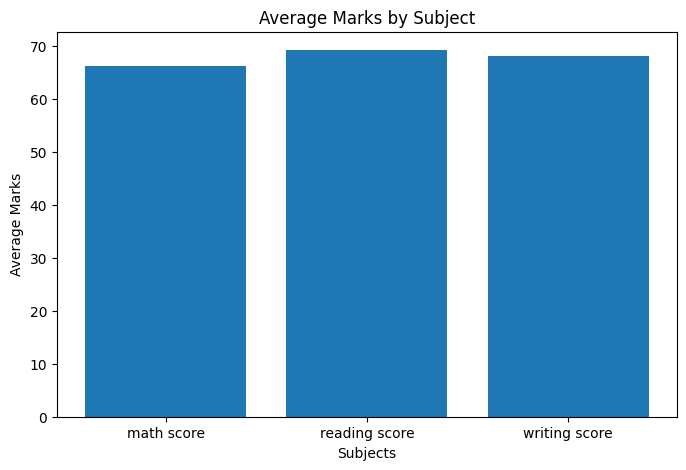

In [21]:

# Calculate average marks in each subject

subjects = ["math score", "reading score", "writing score"]

averages = df[subjects].mean()

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(averages.index, averages.values)

plt.title("Average Marks by Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")

plt.show()


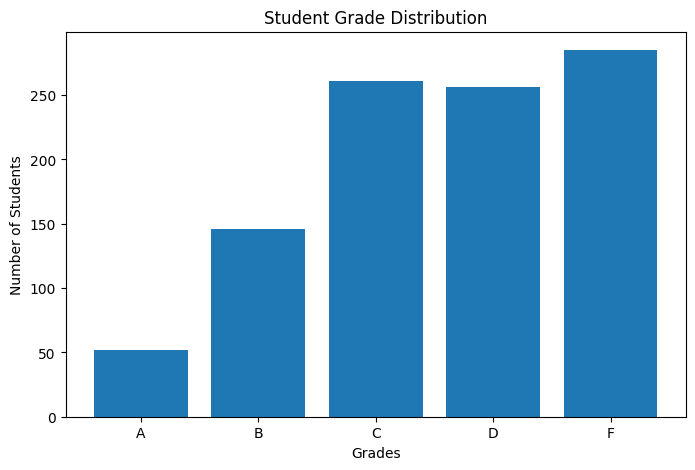

In [22]:

# Count students in each grade

grade_counts = df["Grade"].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(grade_counts.index, grade_counts.values)

plt.title("Student Grade Distribution")
plt.xlabel("Grades")
plt.ylabel("Number of Students")

plt.show()


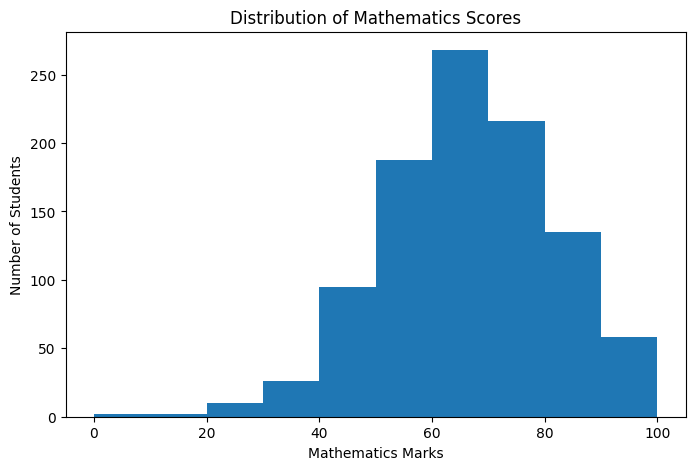

In [23]:

plt.figure(figsize=(8, 5))

plt.hist(df["math score"], bins=10)

plt.title("Distribution of Mathematics Scores")
plt.xlabel("Mathematics Marks")
plt.ylabel("Number of Students")

plt.show()


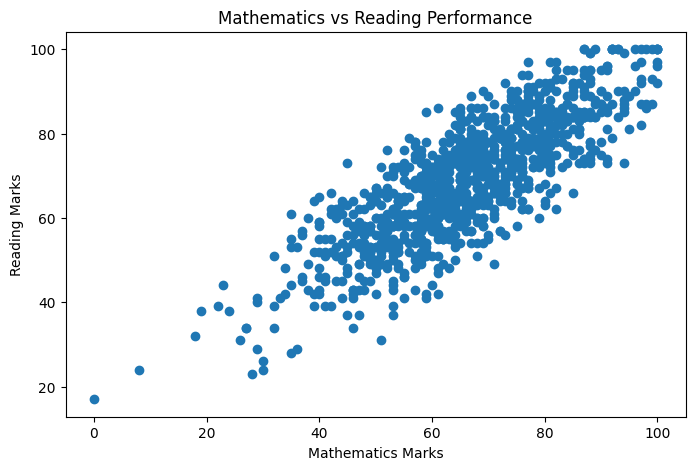

In [24]:

plt.figure(figsize=(8, 5))

plt.scatter(df["math score"], df["reading score"])

plt.title("Mathematics vs Reading Performance")
plt.xlabel("Mathematics Marks")
plt.ylabel("Reading Marks")

plt.show()


In [25]:

# Save analyzed dataset

df.to_csv("Student_Performance_Results.csv", index=False)

print("Student performance analysis saved successfully!")


Student performance analysis saved successfully!


In [26]:
from google.colab import files

files.download("Student_Performance_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:

# Overall student performance

print("Total Students:", len(df))

print("\nOverall Average Score:",
      round(df["Average Score"].mean(), 2))

print("\nSubject-wise Average Marks:")
print(df[["math score", "reading score",
          "writing score"]].mean().round(2))

print("\nGrade Distribution:")
print(df["Grade"].value_counts().sort_index())

print("\nHighest Student Average:",
      round(df["Average Score"].max(), 2))

print("\nLowest Student Average:",
      round(df["Average Score"].min(), 2))


Total Students: 1000

Overall Average Score: 67.77

Subject-wise Average Marks:
math score       66.09
reading score    69.17
writing score    68.05
dtype: float64

Grade Distribution:
Grade
A     52
B    146
C    261
D    256
F    285
Name: count, dtype: int64

Highest Student Average: 100.0

Lowest Student Average: 9.0
